In [1]:
import hashlib
import os
import platform
import uuid

STUDENT_ID = 20244080327

CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV")
print(f"[Conda 环境] {CONDA_ENV}")

MACHINE_FP = hashlib.sha256(
    f"{platform.node()}|{platform.machine()}|{platform.system()}|{uuid.getnode()}".encode()
).hexdigest()[:16]
RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"
print(f"[学号] {STUDENT_ID}")
print(f"[机器指纹] {MACHINE_FP}")
print(f"[RUN_ID] {RUN_ID}")

[Conda 环境] exp01_env
[学号] 20244080327
[机器指纹] 46a1c7c268488908
[RUN_ID] 20244080327-46a1c7c268488908


wigner_density(0): 0.3183098861837907
wigner_density(2.5): 0.0


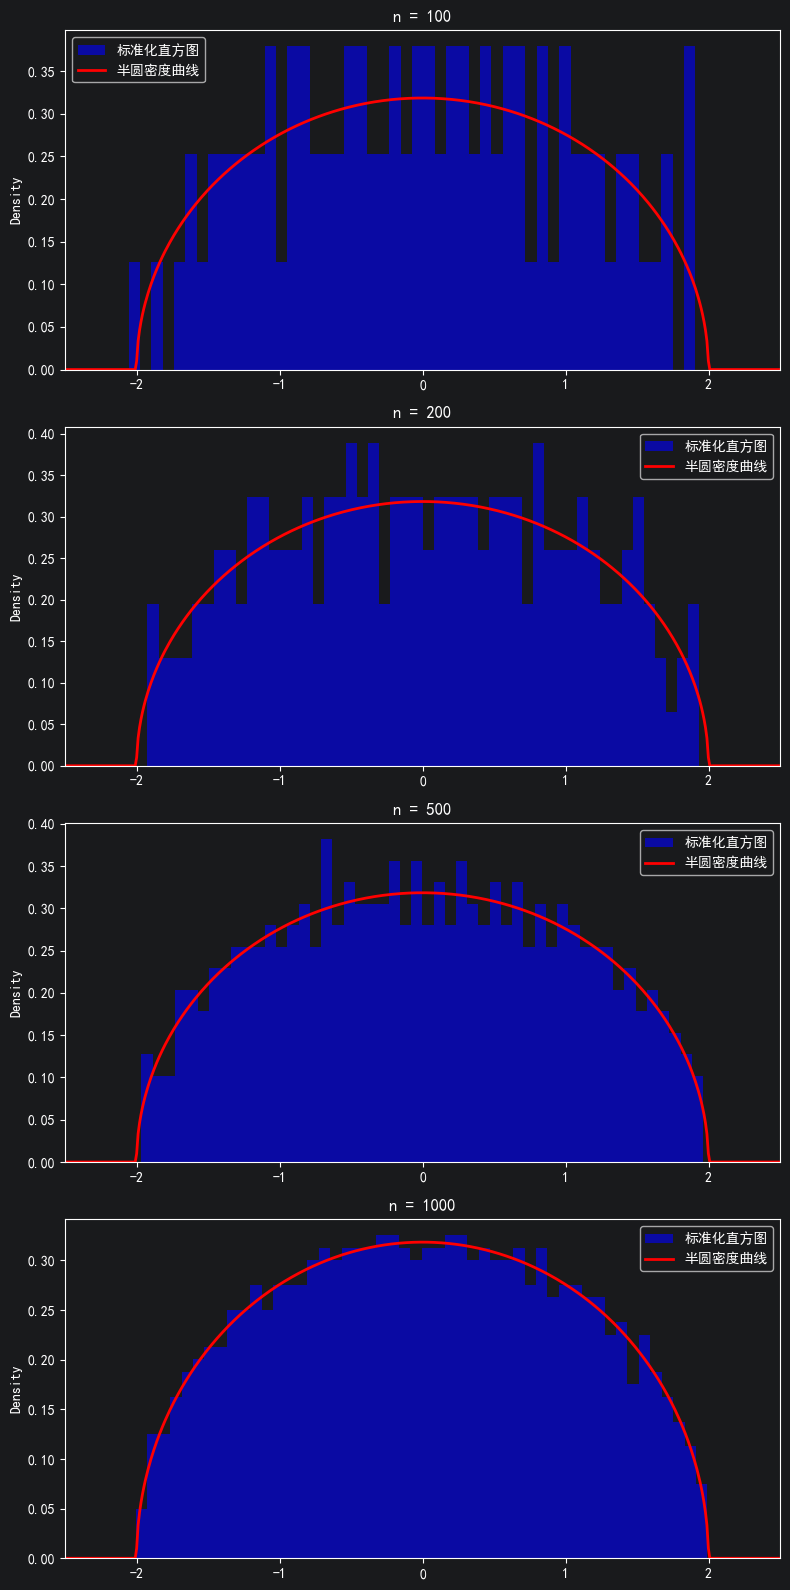


【结论】从图中可以看出，当 n=100 时直方图波动较大；当 n 达到 500 至 1000 时，蓝色直方图与红色理论曲线已非常贴合。因此 n 大约达到 500～1000 时，半圆密度能较好地拟合特征值分布。


In [2]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False

def wigner_density(x):
    if np.isscalar(x):
        return float(np.sqrt(4 - x**2) / (2 * np.pi)) if abs(x) <= 2 else 0.0
    x = np.asarray(x)
    return np.where(np.abs(x) <= 2, np.sqrt(np.maximum(4 - x**2, 0)) / (2 * np.pi), 0.0)

def generate_wigner(n):
    if not isinstance(n, (int, np.integer)) or isinstance(n, bool) or n <= 0:
        raise ValueError("n 必须是正整数")
    A = np.random.normal(0, np.sqrt(1.0 / n), size=(n, n))
    Z = np.triu(A) + np.triu(A, 1).T
    return Z

def get_spectrum(matrix):
    eigvals = np.linalg.eigvalsh(matrix)
    return np.sort(eigvals)

print("wigner_density(0):", wigner_density(0))
print("wigner_density(2.5):", wigner_density(2.5))

np.random.seed(42)
ns = [100, 200, 500, 1000]
fig, axes = plt.subplots(4, 1, figsize=(8, 16))
x_vals = np.linspace(-2.5, 2.5, 500)
y_vals = wigner_density(x_vals)

for ax, n in zip(axes, ns):
    Z = generate_wigner(n)
    eigvals = get_spectrum(Z)
    ax.hist(eigvals, bins=50, density=True, color='blue', alpha=0.6, label='标准化直方图')
    ax.plot(x_vals, y_vals, color='red', linewidth=2, label='半圆密度曲线')
    ax.set_title(f"n = {n}")
    ax.set_xlim(-2.5, 2.5)
    ax.set_ylabel("Density")
    ax.legend()

plt.tight_layout()
plt.show()

print("\n【结论】从图中可以看出，当 n=100 时直方图波动较大；当 n 达到 500 至 1000 时，蓝色直方图与红色理论曲线已非常贴合。因此 n 大约达到 500～1000 时，半圆密度能较好地拟合特征值分布。")

1. `wigner_density`：实现半圆密度函数。判断输入是否在 \([-2, 2]\) 之间，使用 `np.sqrt` 计算。
2. `generate_wigner`：生成随机对称矩阵。上三角元素服从 \(N(0, 1/n)\)，再通过转置补齐下三角。
3. `get_spectrum`：使用 `np.linalg.eigvalsh` 高效计算对称矩阵的特征值，并按非递减排序。
4. 绘图：使用 `plt.subplots` 创建四个纵向子图，用蓝色标准化直方图展示特征值，叠加红色理论曲线。

是否有效棋盘: True
下一步的棋盘:
 [[0 0 0 0 0]
 [1 0 1 0 0]
 [0 1 1 0 0]
 [0 1 0 0 0]
 [0 0 0 0 0]]

【绘图】原始滑翔机形态：


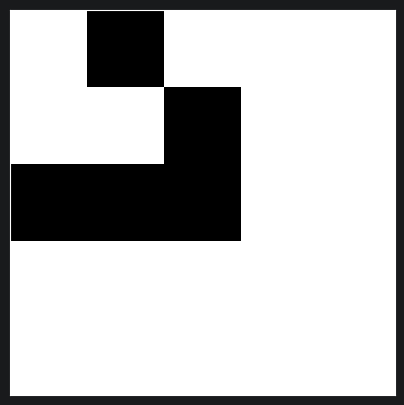

In [3]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False

def is_valid_board(board):
    if not isinstance(board, np.ndarray):
        return False
    if board.ndim != 2:
        return False
    return bool(np.isin(board, [0, 1]).all())

def gol_step(board):
    if not is_valid_board(board):
        raise ValueError("输入不是有效的生命游戏棋盘")

    neighbors = np.zeros_like(board, dtype=int)
    for dr in [-1, 0, 1]:
        for dc in [-1, 0, 1]:
            if dr == 0 and dc == 0:
                continue
            neighbors += np.roll(np.roll(board, dr, axis=0), dc, axis=1)

    new_board = np.zeros_like(board)
    new_board[(board == 1) & ((neighbors == 2) | (neighbors == 3))] = 1
    new_board[(board == 0) & (neighbors == 3)] = 1
    return new_board

def draw_gol_board(board):
    if not is_valid_board(board):
        raise ValueError("输入不是有效的生命游戏棋盘")
    plt.figure(figsize=(5, 5))
    plt.imshow(board, cmap=plt.get_cmap('gray_r'), interpolation='nearest')
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.show()

glider = np.array([
    [0, 1, 0, 0, 0],
    [0, 0, 1, 0, 0],
    [1, 1, 1, 0, 0],
    [0, 0, 0, 0, 0],
    [0, 0, 0, 0, 0]
])
print("是否有效棋盘:", is_valid_board(glider))
print("下一步的棋盘:\n", gol_step(glider))
print("\n【绘图】原始滑翔机形态：")
draw_gol_board(glider)

1. `is_valid_board`：检查是否为 NumPy 的二维数组，且元素仅为 0 或 1。
2. `gol_step`：利用 `np.roll` 计算 8 个方向的邻居数。`np.roll` 本身具有“首尾相接”的特性，完美契合环绕边界的要求。最后利用布尔索引同时更新活细胞和死细胞。
3. `draw_gol_board`：使用 `plt.imshow` 绘制棋盘，选用 `gray_r` 颜色映射（0为白，1为黑），并隐藏坐标轴与网格线。

In [4]:
import pandas as pd
from IPython.display import display

file_path = r"D:\archive\iris.csv"
iris = pd.read_csv(file_path, index_col=0)

iris['species'] = ['setosa'] * 50 + ['versicolor'] * 50 + ['virginica'] * 50

print("1. 数据集共有多少个数据点:", len(iris))
print("\n2. 每列的数据类型:\n", iris.dtypes)
print("\n3. 列名是什么:", iris.columns.tolist())
print("\n4. 数据中有多少种花卉:", iris['species'].nunique(), "种")
print("分别是:", iris['species'].unique())

cols = ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)', 'species']
iris.loc[34, cols] = [4.9, 3.1, 1.5, 0.2, "setosa"]
iris.loc[37, cols] = [4.9, 3.6, 1.4, 0.1, "setosa"]

print("\n--- 修改后的两行数据 ---")
display(iris.loc[[34, 37]])

iris['Petal.Ratio'] = (iris['petal length (cm)'] / iris['petal width (cm)']).round(3)
iris['Sepal.Ratio'] = (iris['sepal length (cm)'] / iris['sepal width (cm)']).round(3)

iris.to_csv("iris_corrected.csv", index=False)
print("\n>>> 已成功将更正并扩展后的数据保存为 iris_corrected.csv <<<")

stats = iris.groupby('species').agg({
    'Petal.Ratio': ['mean', 'median', 'min', 'max', 'std'],
    'Sepal.Ratio': ['mean', 'median', 'min', 'max', 'std']
})

print("\n--- 分组统计结果 ---")
display(stats.round(3))

1. 数据集共有多少个数据点: 150

2. 每列的数据类型:
 sepal length (cm)    float64
sepal width (cm)     float64
petal length (cm)    float64
petal width (cm)     float64
species               object
dtype: object

3. 列名是什么: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)', 'species']

4. 数据中有多少种花卉: 3 种
分别是: ['setosa' 'versicolor' 'virginica']

--- 修改后的两行数据 ---


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
34,4.9,3.1,1.5,0.2,setosa
37,4.9,3.6,1.4,0.1,setosa



>>> 已成功将更正并扩展后的数据保存为 iris_corrected.csv <<<

--- 分组统计结果 ---


Petal.Ratio                            Sepal.Ratio                \
                  mean median    min   max    std        mean median    min   
species                                                                       
setosa           6.908  7.000  2.667  15.0  2.855       1.471  1.467  1.268   
versicolor       3.182  3.231  0.336   4.1  0.516       2.166  2.161  1.765   
virginica        2.781  2.667  2.125   4.0  0.407       2.230  2.170  1.824   

                          
              max    std  
species                   
setosa      1.957  0.120  
versicolor  2.818  0.228  
virginica   2.962  0.247